# From waveform to log-mel spectrogram

A generated ten-second tone makes the production frontend easy to inspect before downloading the full MIMII dataset.

In [1]:
from pathlib import Path
import os
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/mimii").is_dir() and (p / "results/fits.json").is_file())
os.chdir(root)
sys.path.insert(0, str(root / "src"))
import json
import numpy as np
from mimii.config import PreprocessConfig
from mimii.features import log_mel_spectrogram
frontend = json.loads(Path("configs/full_dataset_logmel.json").read_text())["frontend"]
cfg = PreprocessConfig(**frontend)
t = np.arange(cfg.expected_samples) / cfg.sample_rate
wave = (0.05 * np.sin(2 * np.pi * 440 * t)).astype(np.float32)

## Extract the time-frequency representation

The production frontend applies a 1,024-sample Hann window, a 512-sample hop, 128 mel filters and a logarithmic power transform.

In [2]:
features = log_mel_spectrogram(wave, cfg)
assert features.shape == (128, 313) and np.isfinite(features).all()
print("Mel bands × time frames:", features.shape)

Mel bands × time frames: (128, 313)


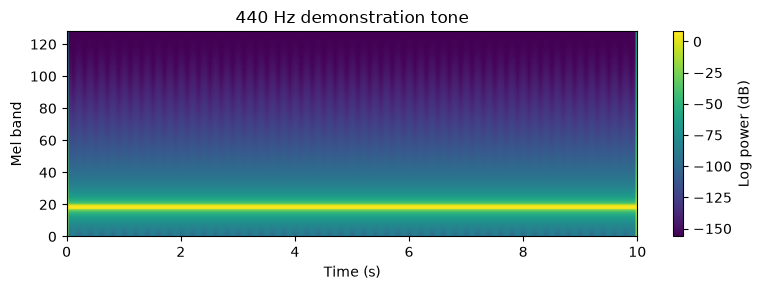

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3))
im = ax.imshow(features, origin="lower", aspect="auto", extent=[0, 10, 0, 128])
ax.set(xlabel="Time (s)", ylabel="Mel band", title="440 Hz demonstration tone")
fig.colorbar(im, ax=ax, label="Log power (dB)")
fig.tight_layout()
plt.show()

## Apply to the full corpus

The pipeline groups all SNR versions of one source together, reserves faults for testing, and estimates per-band normalization from healthy training recordings. Follow the [reproduction guide](../REPRODUCE.md) to download the data and run the grouped split and feature audit.